# 02_train_baseline_model (NACC) — Updated

Trains a simple baseline 4-class classifier using `output/cohort.csv` produced by `01_build_cohort`.


Vascular Composite Engineering (E8)
Raw vascular risk variables were replaced with:
•	VASC_RISK_COUNT
•	VASC_MED_COUNT
•	STROKE_TIA_ANY
To reduce multicollinearity and improve balanced accuracy slightly (~+0.002–0.003).
Conclusion:
Aggregated vascular burden provided modest improvement but did not dramatically improve subtype separability.

In [34]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier


exp_name = "E8b_vascular_signal"
H = 5  # horizon years used in build_cohort notebook

OUT_DIR = os.path.join("..", "output")

cohort_file = f"cohort_{exp_name}_H{H}.csv"
DATA_PATH = os.path.join(OUT_DIR, cohort_file)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Could not find cohort file: {DATA_PATH}\n"
        f"Make sure 01_build_cohort exported: {cohort_file}"
    )

df = pd.read_csv(DATA_PATH)

print("Loaded:", cohort_file, df.shape)
print(df["label"].value_counts(dropna=False))
df.head()

Loaded: cohort_E8b_vascular_signal_H5.csv (38341, 85)
label
Censored         23300
NoDementia_Hy    11083
AD                3013
MixedOrOther       504
PD_LBD             289
Vascular           152
Name: count, dtype: int64


,NACCID,baseline_date,label,max_follow_years,has_H_followup,has_dementia_H,NACCAGE,SEX,RACE,HISPANIC,...,STROKMUL,COMMUN,HOMEHOBB,PERSCARE,MEMORY,ORIENT,JUDGMENT,NACCMOM,NACCDAD,SIVDFIND
0,NACC000011,2006-04-17,Censored,3.296372,False,False,62.0,2.0,1.0,0.0,...,NaN,0.0,0.0,0.0,0.5,0.0,0.0,NaN,NaN,NaN
1,NACC000034,2015-07-16,NoDementia_Hy,6.986995,True,False,79.0,2.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.5,0.0,0.0,1.0,1.0,0.0
2,NACC000067,2012-05-23,Censored,2.088980,False,False,60.0,1.0,1.0,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0.5,1.0,0.0,NaN
3,NACC000073,2016-05-20,Censored,0.000000,False,False,44.0,2.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,NACC000138,2023-07-13,Censored,1.043121,False,False,54.0,2.0,50.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [35]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score, f1_score
from sklearn.utils.class_weight import compute_sample_weight

import matplotlib.pyplot as plt

# FIG_DIR = os.path.join(OUT_DIR, "figs_baseline")
# os.makedirs(FIG_DIR, exist_ok=True)

RANDOM_STATE = 42

## Keep only the 4-class task

In [36]:
def fix_categorical_codes(X):
    X = X.copy()
    CAT_CODE_VARS = [c for c in ["SEX", "RACE", "HISPANIC", "NACCUDSD"] if c in X.columns]
    STD_MISS = {-4, 9}

    for c in CAT_CODE_VARS:
        s = pd.to_numeric(X[c], errors="coerce")
        s = s.mask(s.isin(list(STD_MISS)), np.nan)
        X[c] = s

    if "RACE" in X.columns:
        X["RACE"] = X["RACE"].mask(X["RACE"].isin([99]), np.nan)

    for c in CAT_CODE_VARS:
        s = pd.to_numeric(X[c], errors="coerce")
        X[c] = s.map(lambda v: np.nan if pd.isna(v) else str(int(v))).astype(object)

    if "EDUC" in X.columns:
        educ_num = pd.to_numeric(X["EDUC"], errors="coerce")
        #X["EDUC_BIN"] = np.where(educ_num <= 12, "<=12", ">12").astype(object)

    X = X.replace({pd.NA: np.nan})
    for c in X.columns:
        if X[c].dtype == "bool":
            X[c] = X[c].astype(int)
    return X

In [37]:
import numpy as np
import pandas as pd


df4 = df.copy()  

# Keeping only non-censored outcome classes for training
KEEP = {"AD", "NoDementia_Hy", "PD_LBD", "Vascular"}
df4 = df4[df4["label"].isin(KEEP)].copy()

print("4-class rows:", len(df4))
print(df4["label"].value_counts())

# Dropping IDs/labels
#y = df4["label"].astype(str)
# drop_cols = [c for c in ["NACCID", "baseline_date", "label"] if c in df4.columns]
#drop_cols = [c for c in [ "NACCID", "baseline_date", "label", "has_H_followup", "has_dementia_H", "max_follow_years", "abs_days_from_baseline"] if c in df4.columns]


def prepare_experiment_df(df, exp_name):
    df = df.copy()

    # columns that are always dropped
    drop_cols = [c for c in ["NACCID","baseline_date","label","has_H_followup","has_dementia_H","max_follow_years","abs_days_from_baseline", "NACCUDSD"]
                 if c in df.columns]

    X = df.drop(columns=[c for c in drop_cols if c in df.columns])
    y = df["label"].astype(str)

    return X, y


from sklearn.model_selection import train_test_split

X, y = prepare_experiment_df(df4, exp_name)

# Applying categorical cleanup before splitting
X = fix_categorical_codes(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train label counts:\n", y_train.value_counts())
print("Test label counts:\n", y_test.value_counts())


def z_from_train(train_s, s):
    mu = train_s.mean()
    sd = train_s.std(ddof=0)
    if pd.isna(sd) or sd == 0:
        return s*0.0
    return (s - mu) / sd

labels = ["AD", "NoDementia_Hy", "PD_LBD", "Vascular"]

4-class rows: 14537
label
NoDementia_Hy    11083
AD                3013
PD_LBD             289
Vascular           152
Name: count, dtype: int64
Train: (11629, 78) Test: (2908, 78)
Train label counts:
 label
NoDementia_Hy    8866
AD               2410
PD_LBD            231
Vascular          122
Name: count, dtype: int64
Test label counts:
 label
NoDementia_Hy    2217
AD                603
PD_LBD             58
Vascular           30
Name: count, dtype: int64


In [38]:
csf_cols = ["CSFABETA", "CSFPTAU", "CSFTTAU"]
present_csf_cols = [c for c in csf_cols if c in df.columns]

if len(present_csf_cols) == len(csf_cols):
    df_csf = df[df[present_csf_cols].notna().all(axis=1)].copy()
    print("CSF subset size:", len(df_csf))
    print(df_csf["label"].value_counts())
else:
    print("CSF columns not present in this dataset:", 
          [c for c in csf_cols if c not in df.columns])

CSF columns not present in this dataset: ['CSFABETA', 'CSFPTAU', 'CSFTTAU']


## Split + preprocess + train

Train/test split

Preprocessing pipelines (sparse for LR/boosting)

In [39]:
# cat_cols = [c for c in X_train.columns if X_train[c].dtype == "object" or str(X_train[c].dtype).startswith("string")]
# num_cols = [c for c in X_train.columns if c not in cat_cols]

import pandas as pd

num_cols = [c for c in X_train.columns if pd.api.types.is_numeric_dtype(X_train[c])]
cat_cols = [c for c in X_train.columns if c not in num_cols]


numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, num_cols),
        ("cat", categorical_pipe, cat_cols),
    ],
    remainder="drop"
)

print("Num cols:", len(num_cols), "Cat cols:", len(cat_cols))
print("Num cols:", num_cols, "Cat cols:", cat_cols)

# print(sorted([c for c in X_train.columns if "VASC" in c or "EXEC" in c or "TRAIL" in c or "MMSE" in c or "MOCA" in c]))
# print(sorted([c for c in X_train.columns]))



Num cols: 75 Cat cols: 3
Num cols: ['NACCAGE', 'EDUC', 'NACCMMSE', 'NACCMOCA', 'TRAILA', 'TRAILB', 'ANIMALS', 'BOSTON', 'CDRSUM', 'CDRGLOB', 'NACCMMSE_missing', 'NACCMOCA_missing', 'TRAILA_missing', 'TRAILB_missing', 'CDRSUM_missing', 'COGFLUC', 'BEVHALL', 'BEREM', 'PARKSIGN', 'BRADY', 'RESTTRL', 'RESTTRR', 'RIGIDL', 'RIGIDR', 'SLOWINGL', 'SLOWINGR', 'PARKGAIT', 'GAITDIS', 'DIABETES', 'HYPERTEN', 'HYPERCHO', 'CVAFIB', 'CBSTROKE', 'CBTIA', 'CVCHF', 'CVANGINA', 'CVBYPASS', 'CVANGIO', 'CVHVALVE', 'CVOTHR', 'APNEA', 'DEP2YRS', 'DIABET', 'POSTINST', 'NACCGDS', 'DIGBACCT', 'DIGBACLS', 'CVD', 'VASC', 'CVDCOG', 'CVDIMAG', 'IMAGMWMH', 'IMAGEWMH', 'FOCLSYM', 'FOCLSIGN', 'HACHIN', 'HACHIN_GE_4', 'HACHIN_GE_7', 'STROKE_TIA_ANY', 'VASC_MED_COUNT', 'GAIT_ANY', 'CDR_ADL_COG_RATIO', 'CDR_ADL_MINUS_COG', 'STROKE_x_EXEC', 'STROKDEC', 'STROKMUL', 'COMMUN', 'HOMEHOBB', 'PERSCARE', 'MEMORY', 'ORIENT', 'JUDGMENT', 'NACCMOM', 'NACCDAD', 'SIVDFIND'] Cat cols: ['SEX', 'RACE', 'HISPANIC']


Model A: Logistic Regression (final settings)

# Logistic Regression (custom weights, C=0.1)

In [40]:
from sklearn.linear_model import LogisticRegression

custom_w = {
    "NoDementia_Hy": 1.0,
    "AD": 2.0,
    "PD_LBD": 6.0,
    "Vascular": 8.0
}

clf_lr = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", LogisticRegression(
        max_iter=8000,
        class_weight=custom_w,
        C=0.1
    ))
])

clf_lr.fit(X_train, y_train)
pred_lr = clf_lr.predict(X_test)
proba_lr = clf_lr.predict_proba(X_test)

print("=== Logistic Regression (custom weights, C=0.1) ===")
print(classification_report(y_test, pred_lr, digits=4))
print("Balanced accuracy:", balanced_accuracy_score(y_test, pred_lr))
print(confusion_matrix(y_test, pred_lr, labels=labels))


=== Logistic Regression (custom weights, C=0.1) ===
               precision    recall  f1-score   support

           AD     0.6616    0.7264    0.6925       603
NoDementia_Hy     0.9321    0.8972    0.9143      2217
       PD_LBD     0.4625    0.6379    0.5362        58
     Vascular     0.3438    0.3667    0.3548        30

     accuracy                         0.8511      2908
    macro avg     0.6000    0.6570    0.6245      2908
 weighted avg     0.8605    0.8511    0.8550      2908

Balanced accuracy: 0.6570310456025598
[[ 438  132   22   11]
 [ 198 1989   20   10]
 [  15    6   37    0]
 [  11    7    1   11]]


Confusion matrix heatmap code

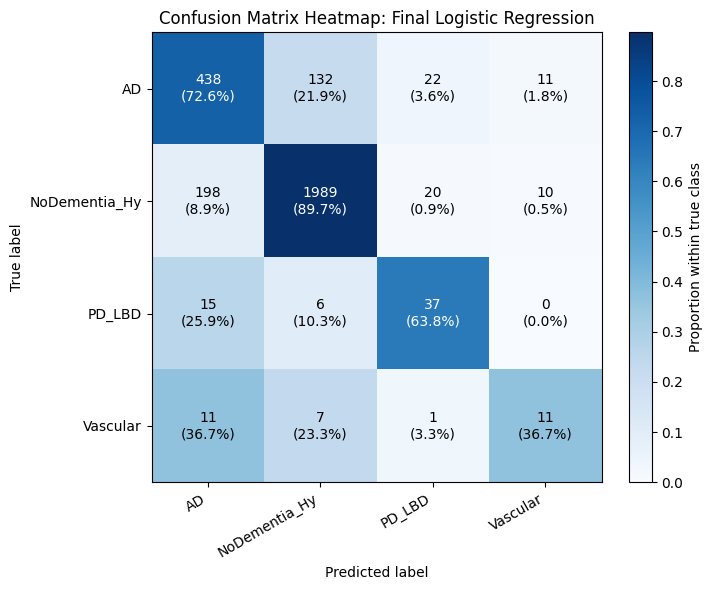

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def save_current_fig(filename: str):
    out = OUT_DIR / filename
    plt.tight_layout()
    plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


# predicted probabilities
proba_lr = clf_lr.predict_proba(X_test)

# confusion matrix
cm = confusion_matrix(y_test, pred_lr, labels=labels)

# row percentages (true-class normalized)
cm_pct = cm / cm.sum(axis=1, keepdims=True)
cm_pct = np.nan_to_num(cm_pct)

plt.figure(figsize=(8, 6))
im = plt.imshow(cm_pct, interpolation="nearest", cmap="Blues")
plt.colorbar(im, fraction=0.046, pad=0.04, label="Proportion within true class")

plt.xticks(np.arange(len(labels)), labels, rotation=30, ha="right")
plt.yticks(np.arange(len(labels)), labels)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix Heatmap: Final Logistic Regression")

# annotate with count + percentage
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        count = cm[i, j]
        pct = cm_pct[i, j] * 100
        text_color = "white" if cm_pct[i, j] > 0.5 else "black"
        plt.text(
            j, i,
            f"{count}\n({pct:.1f}%)",
            ha="center", va="center",
            color=text_color, fontsize=10
        )

plt.tight_layout()
# save_current_fig("confusion_matrix_heatmap_final_lr.png")
plt.show()

Multi-class ROC curve code

TypeError: unsupported operand type(s) for /: 'str' and 'str'

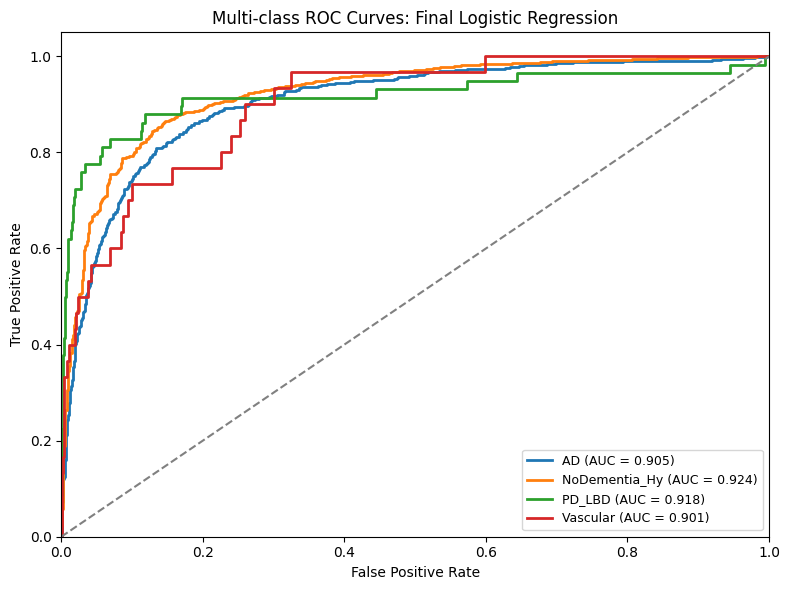

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# predicted probabilities
proba_lr = clf_lr.predict_proba(X_test)

# binarize true labels
y_test_bin = label_binarize(y_test, classes=labels)

plt.figure(figsize=(8, 6))

auc_dict = {}

for i, cls in enumerate(labels):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba_lr[:, i])
    roc_auc = auc(fpr, tpr)
    auc_dict[cls] = roc_auc
    plt.plot(fpr, tpr, linewidth=2, label=f"{cls} (AUC = {roc_auc:.3f})")

# diagonal reference
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1.5, color="gray")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-class ROC Curves: Final Logistic Regression")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
save_current_fig(f"multiclass_roc_curves_final_lr.png")

# plt.savefig("multiclass_roc_lr.png", dpi=300, bbox_inches="tight")

plt.show()

print("AUC by class:")
for k, v in auc_dict.items():
    print(f"{k}: {v:.4f}")

# Creating joblib file for webapp

In [47]:
import joblib
from pathlib import Path

DEMO_OUT_DIR = Path("demo_export")
DEMO_OUT_DIR.mkdir(exist_ok=True)

joblib.dump(clf_lr, DEMO_OUT_DIR / "model.joblib")
joblib.dump(list(clf_lr.named_steps["model"].classes_), DEMO_OUT_DIR / "class_names.joblib")

defaults = {}
for col in X_train.columns:
    if str(X_train[col].dtype) in ["object", "category", "bool"]:
        mode_vals = X_train[col].mode(dropna=True)
        defaults[col] = mode_vals.iloc[0] if len(mode_vals) else ""
    else:
        defaults[col] = float(X_train[col].median())

joblib.dump(defaults, DEMO_OUT_DIR / "defaults.joblib")

print("Saved:")
print(DEMO_OUT_DIR / "model.joblib")
print(DEMO_OUT_DIR / "class_names.joblib")
print(DEMO_OUT_DIR / "defaults.joblib")
print("Class order:", list(clf_lr.named_steps["model"].classes_))

Saved:
demo_export\model.joblib
demo_export\class_names.joblib
demo_export\defaults.joblib
Class order: ['AD', 'NoDementia_Hy', 'PD_LBD', 'Vascular']


# Creating outputs and joblib files for SHAP

In [9]:
import joblib
import pandas as pd

# Plain model predictions
proba = clf_lr.predict_proba(X_test)
preds = clf_lr.predict(X_test)
class_order = clf_lr.named_steps["model"].classes_

# Save model bundle
joblib.dump(
    {
        "model": clf_lr,
        "class_order": list(class_order),
        "feature_cols": list(X_train.columns),
        "model_name": "LogisticRegression_custom_weights_C0.1",
        "uses_vascular_threshold": False
    },
    "../output/dementia_classifier_bundle.joblib"
)

print("Model bundle saved.")

# Export predictions
clf_preds = pd.DataFrame({
    "NACCID": df4.loc[X_test.index, "NACCID"].values,
    "true_class": y_test.values,
    "predicted_class": preds
})

for i, cls in enumerate(class_order):
    clf_preds[f"prob_{cls}"] = proba[:, i]

clf_preds.to_csv("../output/classifier_predictions.csv", index=False)

print("Saved ../output/classifier_predictions.csv")
display(clf_preds.head())

Model bundle saved.
Saved ../output/classifier_predictions.csv


,NACCID,true_class,predicted_class,prob_AD,prob_NoDementia_Hy,prob_PD_LBD,prob_Vascular
0,NACC056862,NoDementia_Hy,NoDementia_Hy,0.081939,0.910434,0.002375,0.005251
1,NACC774813,NoDementia_Hy,NoDementia_Hy,0.079952,0.914570,0.003639,0.001838
2,NACC989206,NoDementia_Hy,NoDementia_Hy,0.062824,0.932811,0.001166,0.003199
3,NACC735141,AD,AD,0.777575,0.084701,0.097183,0.040540
4,NACC252819,NoDementia_Hy,AD,0.573230,0.379412,0.012352,0.035007


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
    precision_recall_fscore_support
)
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

# --------------------------------------------------
# 0) Labels / weights
# --------------------------------------------------
labels = ["AD", "NoDementia_Hy", "PD_LBD", "Vascular"]

# Slightly reduced vascular weight to help precision/F1
custom_w = {
    "NoDementia_Hy": 1.0,
    "AD": 2.0,
    "PD_LBD": 5.0,
    "Vascular": 6.0
}

# --------------------------------------------------
# 1) Train / validation split from TRAIN only
# --------------------------------------------------
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# --------------------------------------------------
# 2) Candidate model settings
#    One model change included: Elastic Net logistic regression
# --------------------------------------------------
model_settings = [
    {
        "name": "LR_L2_C0.1",
        "solver": "lbfgs",
        "C": 0.1,
        "l1_ratio": 0,   # pure L2
    },
    {
        "name": "LR_L2_C0.05",
        "solver": "lbfgs",
        "C": 0.05,
        "l1_ratio": 0,   # pure L2
    },
    {
        "name": "LR_ElasticNet_C0.1_l1r0.2",
        "solver": "saga",
        "C": 0.1,
        "l1_ratio": 0.2,   # ElasticNet
    },
    {
        "name": "LR_ElasticNet_C0.05_l1r0.2",
        "solver": "saga",
        "C": 0.05,
        "l1_ratio": 0.2,
    },
]

thresholds = np.linspace(0.05, 0.40, 36)

# --------------------------------------------------
# Helper: apply vascular threshold override
# --------------------------------------------------
def predict_with_vascular_threshold(proba, class_order, threshold):
    vas_idx = list(class_order).index("Vascular")
    preds = []
    for p in proba:
        if p[vas_idx] >= threshold:
            preds.append("Vascular")
        else:
            preds.append(class_order[np.argmax(p)])
    return np.array(preds)

# --------------------------------------------------
# 3) Validation search:
#    choose model + threshold by vascular F1
#    tie-breakers: macro F1, balanced accuracy
# --------------------------------------------------
search_rows = []

for cfg in model_settings:
    clf = Pipeline(steps=[
        ("preprocess", preprocess),
        ("model", LogisticRegression(
            max_iter=50000,
            tol=1e-4,          # tighter convergence tolerance
            class_weight=custom_w,
            C=cfg["C"],
            # penalty=cfg["penalty"],
            solver=cfg["solver"],
            l1_ratio=cfg["l1_ratio"],
            # n_jobs=None
        ))
    ])

    clf.fit(X_tr, y_tr)

    proba_val = clf.predict_proba(X_val)
    class_order = clf.named_steps["model"].classes_

    for T in thresholds:
        preds_val = predict_with_vascular_threshold(proba_val, class_order, T)

        # overall metrics
        ba = balanced_accuracy_score(y_val, preds_val)
        macro_f1 = f1_score(y_val, preds_val, average="macro")

        # per-class metrics
        p_arr, r_arr, f_arr, s_arr = precision_recall_fscore_support(
            y_val, preds_val, labels=labels, zero_division=0
        )

        metric_map = {
            lab: {"precision": p, "recall": r, "f1": f, "support": s}
            for lab, p, r, f, s in zip(labels, p_arr, r_arr, f_arr, s_arr)
        }

        vprec = metric_map["Vascular"]["precision"]
        vrec  = metric_map["Vascular"]["recall"]
        vf1   = metric_map["Vascular"]["f1"]

        search_rows.append({
            "model_name": cfg["name"],
            # "penalty": cfg["penalty"],
            "solver": cfg["solver"],
            "C": cfg["C"],
            "l1_ratio": cfg["l1_ratio"],
            "threshold": T,
            "val_bal_acc": ba,
            "val_macro_f1": macro_f1,
            "val_vasc_precision": vprec,
            "val_vasc_recall": vrec,
            "val_vasc_f1": vf1,
        })

search_df = pd.DataFrame(search_rows)

# Sort by vascular F1 first, then macro F1, then BA
search_df = search_df.sort_values(
    ["val_vasc_f1", "val_macro_f1", "val_bal_acc"],
    ascending=[False, False, False]
).reset_index(drop=True)

print("Top validation settings:")
display(search_df.head(10))

best_row = search_df.iloc[0]
best_model_name = best_row["model_name"]
best_T = float(best_row["threshold"])

print(
    f"Best setting: {best_model_name} | "
    f"T_VAS={best_T:.3f} | "
    f"val VascF1={best_row['val_vasc_f1']:.4f} | "
    f"val MacroF1={best_row['val_macro_f1']:.4f} | "
    f"val BA={best_row['val_bal_acc']:.4f} | "
    f"val VascPrec={best_row['val_vasc_precision']:.4f} | "
    f"val VascRec={best_row['val_vasc_recall']:.4f}"
)


c:\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Top validation settings:


,model_name,solver,C,l1_ratio,threshold,val_bal_acc,val_macro_f1,val_vasc_precision,val_vasc_recall,val_vasc_f1
0,LR_ElasticNet_C0.1_l1r0.2,saga,0.10,0.2,0.39,0.635921,0.616362,0.210526,0.32,0.253968
1,LR_ElasticNet_C0.1_l1r0.2,saga,0.10,0.2,0.40,0.635921,0.616362,0.210526,0.32,0.253968
2,LR_ElasticNet_C0.1_l1r0.2,saga,0.10,0.2,0.38,0.634743,0.612740,0.195122,0.32,0.242424
3,LR_L2_C0.05,lbfgs,0.05,0.0,0.39,0.629941,0.608527,0.205882,0.28,0.237288
4,LR_L2_C0.05,lbfgs,0.05,0.0,0.40,0.629941,0.608527,0.205882,0.28,0.237288
5,LR_ElasticNet_C0.1_l1r0.2,saga,0.10,0.2,0.34,0.634224,0.610800,0.186047,0.32,0.235294
6,LR_ElasticNet_C0.1_l1r0.2,saga,0.10,0.2,0.35,0.634224,0.610800,0.186047,0.32,0.235294
7,LR_ElasticNet_C0.1_l1r0.2,saga,0.10,0.2,0.36,0.634224,0.610800,0.186047,0.32,0.235294
8,LR_ElasticNet_C0.1_l1r0.2,saga,0.10,0.2,0.37,0.634224,0.610800,0.186047,0.32,0.235294
9,LR_L2_C0.1,lbfgs,0.10,0.0,0.38,0.629045,0.607060,0.200000,0.28,0.233333


Best setting: LR_ElasticNet_C0.1_l1r0.2 | T_VAS=0.390 | val VascF1=0.2540 | val MacroF1=0.6164 | val BA=0.6359 | val VascPrec=0.2105 | val VascRec=0.3200


In [20]:
# --------------------------------------------------
# 4) Refit best model on FULL TRAIN
# --------------------------------------------------

# clf_best = Pipeline(steps=[
#     ("preprocess", preprocess),
#     ("model", LogisticRegression(
#         max_iter=12000,
#         class_weight=custom_w,
#         C=0.1,
#         penalty="elasticnet",
#         solver="saga",
#         l1_ratio=0.2,
#         n_jobs=None
#     ))
# ])


# best_T = 0.330

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
    precision_recall_fscore_support
)

# applying vascular threshold override
def predict_with_vascular_threshold(proba, class_order, threshold):
    vas_idx = list(class_order).index("Vascular")
    preds = []
    for p in proba:
        if p[vas_idx] >= threshold:
            preds.append("Vascular")
        else:
            preds.append(class_order[np.argmax(p)])
    return np.array(preds)

clf_best = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", LogisticRegression(
        max_iter=12000,
        tol=1e-4, 
        class_weight=custom_w,
        C=0.01,
        # penalty="elasticnet",
        solver="saga",
        l1_ratio=0.2,
        n_jobs=None
    ))
])


best_T = 0.390

clf_best.fit(X_train, y_train)

class_order = clf_best.named_steps["model"].classes_
proba_test = clf_best.predict_proba(X_test)
preds_test = predict_with_vascular_threshold(proba_test, class_order, best_T)

# --------------------------------------------------
# 5) Final test evaluation
# --------------------------------------------------
print("\n=== Logistic Regression (best model + vascular threshold tuned by Vascular F1) ===")
print(classification_report(y_test, preds_test, digits=4, labels=labels, zero_division=0))

test_bal_acc = balanced_accuracy_score(y_test, preds_test)
test_macro_f1 = f1_score(y_test, preds_test, average="macro")
test_weighted_f1 = f1_score(y_test, preds_test, average="weighted")
test_cm = confusion_matrix(y_test, preds_test, labels=labels)

print("Balanced accuracy:", test_bal_acc)
print("Macro F1:", test_macro_f1)
print("Weighted F1:", test_weighted_f1)
print(confusion_matrix(y_test, preds_test, labels=labels))

# Optional: print vascular-specific test metrics cleanly
p_arr, r_arr, f_arr, s_arr = precision_recall_fscore_support(
    y_test, preds_test, labels=labels, zero_division=0
)
test_metric_map = {
    lab: {"precision": p, "recall": r, "f1": f, "support": s}
    for lab, p, r, f, s in zip(labels, p_arr, r_arr, f_arr, s_arr)
}

print("\nTest vascular metrics:")
print(test_metric_map["Vascular"])


=== Logistic Regression (best model + vascular threshold tuned by Vascular F1) ===
               precision    recall  f1-score   support

           AD     0.6697    0.7297    0.6984       603
NoDementia_Hy     0.9322    0.8999    0.9158      2217
       PD_LBD     0.5325    0.7069    0.6074        58
     Vascular     0.2941    0.3333    0.3125        30

     accuracy                         0.8549      2908
    macro avg     0.6071    0.6674    0.6335      2908
 weighted avg     0.8632    0.8549    0.8583      2908

Balanced accuracy: 0.667444868962391
Macro F1: 0.6335219589774042
Weighted F1: 0.8583234334184775
[[ 440  133   18   12]
 [ 193 1995   18   11]
 [  12    4   41    1]
 [  12    8    0   10]]

Test vascular metrics:
{'precision': np.float64(0.29411764705882354), 'recall': np.float64(0.3333333333333333), 'f1': np.float64(0.3125), 'support': np.int64(30)}


c:\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [21]:
import joblib
import pandas as pd

# Save model bundle for the final logistic regression model
joblib.dump(
    {
        "model": clf_best,
        "threshold": best_T,
        "class_order": list(class_order),
        "feature_cols": list(X_train.columns),
        "model_name": "Logistic Regression_best_model_vascular_threshold_tuned_by_Vascular_F1)",
        "uses_vascular_threshold": True
    },
    "../output/dementia_classifier_bundle.joblib"
)


print("Model bundle saved.")

# Predict on test set using probabilities + vascular threshold
proba = clf_best.predict_proba(X_test)
preds = predict_with_vascular_threshold(proba, class_order, best_T)

# Export predictions with true NACCID from df4
clf_preds = pd.DataFrame({
    "NACCID": df4.loc[X_test.index, "NACCID"].values,
    "true_class": y_test.values,
    "predicted_class": preds
})

# Save class probabilities
for i, cls in enumerate(class_order):
    clf_preds[f"prob_{cls}"] = proba[:, i]

clf_preds["vascular_threshold"] = best_T

clf_preds.to_csv("../output/classifier_predictions.csv", index=False)

print("Saved ../output/classifier_predictions.csv")
display(clf_preds.head())

Model bundle saved.
Saved ../output/classifier_predictions.csv


,NACCID,true_class,predicted_class,prob_AD,prob_NoDementia_Hy,prob_PD_LBD,prob_Vascular,vascular_threshold
0,NACC056862,NoDementia_Hy,NoDementia_Hy,0.079969,0.909355,0.004924,0.005752,0.39
1,NACC774813,NoDementia_Hy,NoDementia_Hy,0.074754,0.917109,0.005327,0.002810,0.39
2,NACC989206,NoDementia_Hy,NoDementia_Hy,0.079413,0.907201,0.006436,0.006951,0.39
3,NACC735141,AD,AD,0.765689,0.112495,0.070714,0.051102,0.39
4,NACC252819,NoDementia_Hy,AD,0.545147,0.390104,0.016881,0.047869,0.39
